<a href="https://colab.research.google.com/github/abdulmoizsoomrocs/Foldr/blob/main/023_24_0291_Lab12_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 12 — Artificial Neural Networks: The Perceptron

## Student Information
- **Name:** Abdul Moiz
- **Roll No / Student ID:** 023-24-0291
- **Section:** H
- **Date:** 11 November 2026

**Dataset:** Iris (scikit-learn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

> **Note:** The uploaded PDF is titled *Lab 12 — ANN: Perceptron*, although the uploaded template filename begins with `Lab11`. This notebook follows the title and task sequence inside the PDF.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [3]:
# Task 1.1 — Weighted sum, step function and prediction

def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    z = weighted_sum(w, x, b)
    return step_function(z)

# Slide 16 check
print("Slide 16 prediction:", predict([0.6, 0.8], [2, 3], -2))

# Slide 17 check
w = [1, -0.5]
b = 0.5
inputs = [[1, 1], [2, 1], [0, 3]]
predictions = [predict(w, x, b) for x in inputs]
print("Slide 17 predictions:", predictions)
print("Expected predictions: [1, 1, 0]")

Slide 16 prediction: 1
Slide 17 predictions: [1, 1, 0]
Expected predictions: [1, 1, 0]


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [4]:
# Task 1.2 — One full pass through the AND gate

X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

w = np.array([0.2, -0.1], dtype=float)
b = 0.0
eta = 0.1
mistakes = 0

for i, (x, y_true) in enumerate(zip(X_and, y_and), start=1):
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    error = y_true - y_hat

    if error != 0:
        mistakes += 1
        w = w + eta * error * x
        b = b + eta * error

    print(f"Row {i}: x={x}, y={y_true}, z={z:.2f}, prediction={y_hat}, error={error}")
    print(f"       updated w={w}, b={b:.2f}")

print("\nFinal weights:", w)
print("Final bias:", b)
print("Number of mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")

Row 1: x=[0 0], y=0, z=0.00, prediction=1, error=-1
       updated w=[ 0.2 -0.1], b=-0.10
Row 2: x=[0 1], y=0, z=-0.20, prediction=0, error=0
       updated w=[ 0.2 -0.1], b=-0.10
Row 3: x=[1 0], y=0, z=0.10, prediction=1, error=-1
       updated w=[ 0.1 -0.1], b=-0.20
Row 4: x=[1 1], y=1, z=-0.20, prediction=0, error=1
       updated w=[0.2 0. ], b=-0.10

Final weights: [0.2 0. ]
Final bias: -0.1
Number of mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [5]:
# Task 2.1 — Train a perceptron from scratch

def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    # Start with all weights and bias equal to zero.
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes_per_epoch = []

    for epoch in range(max_epochs):
        mistakes = 0

        # zip pairs each input row with its correct label.
        for x, y_true in zip(X, y):
            y_hat = step_function(np.dot(w, x) + b)
            error = y_true - y_hat

            if error != 0:
                w = w + eta * error * x
                b = b + eta * error
                mistakes += 1

        mistakes_per_epoch.append(mistakes)

        # Stop when an entire epoch has no mistakes.
        if mistakes == 0:
            break

    return w, b, mistakes_per_epoch

# Train on the OR logic gate.
X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])

w_or, b_or, or_mistakes = train_perceptron(X_or, y_or)
print("Final weights:", w_or)
print("Final bias:", b_or)
print("Mistakes per epoch:", or_mistakes)
print("Epochs used:", len(or_mistakes))

Final weights: [0.1 0.1]
Final bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]
Epochs used: 4


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

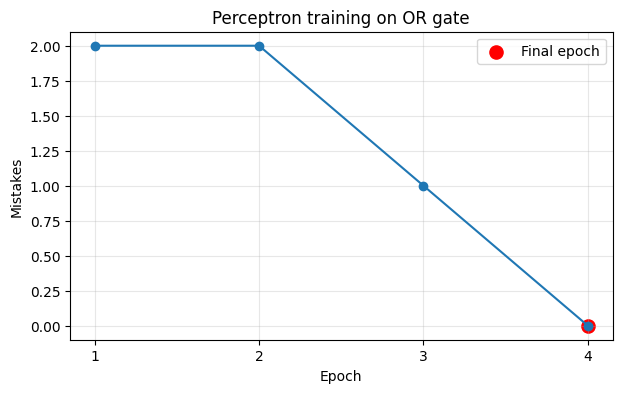

In [6]:
# Task 2.2 — Plot mistakes per epoch

epochs = np.arange(1, len(or_mistakes) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, or_mistakes, marker='o')
plt.scatter(epochs[-1], or_mistakes[-1], color='red', s=90, label='Final epoch')
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.title("Perceptron training on OR gate")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation:** The number of mistakes decreases as the perceptron updates its weights. It stops after reaching an epoch with zero mistakes, meaning it has correctly classified all four OR examples.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

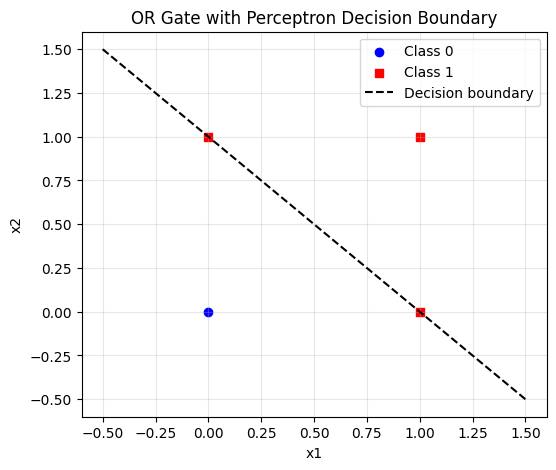

Prediction is 1 on the side where w1*x1 + w2*x2 + b >= 0.


In [7]:
# Task 3.1 — Plot the OR gate and its decision boundary

def plot_boundary(ax, w, b, x_min=-0.5, x_max=1.5):
    x1 = np.linspace(x_min, x_max, 100)

    if np.isclose(w[1], 0):
        # If w2 is zero, the boundary is a vertical line.
        if not np.isclose(w[0], 0):
            ax.axvline(-b / w[0], color='black', linestyle='--', label='Decision boundary')
    else:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, 'k--', label='Decision boundary')

plt.figure(figsize=(6, 5))
ax = plt.gca()
ax.scatter(X_or[y_or == 0, 0], X_or[y_or == 0, 1],
           color='blue', marker='o', label='Class 0')
ax.scatter(X_or[y_or == 1, 0], X_or[y_or == 1, 1],
           color='red', marker='s', label='Class 1')
plot_boundary(ax, w_or, b_or)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('OR Gate with Perceptron Decision Boundary')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

print("Prediction is 1 on the side where w1*x1 + w2*x2 + b >= 0.")

**Interpretation:** *your answer here*

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

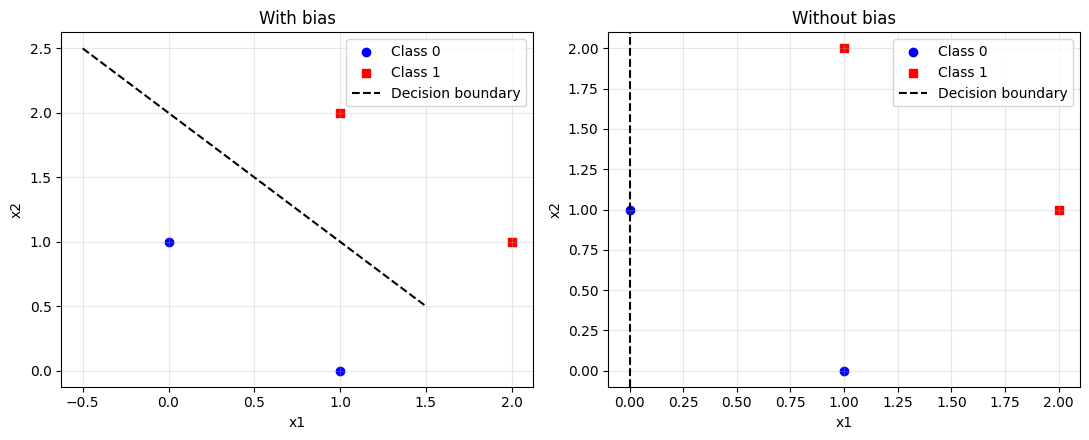

With bias — weights: [0.1 0.1] bias: -0.2 mistakes by epoch: [2, 3, 1, 0]
Without bias — weights: [0.1 0. ] bias: 0.0 mistakes by epoch: [3, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2]
With bias converged: True
Without bias converged: False


In [8]:
# Task 3.2 — Train with bias and without bias

def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    w = np.zeros(X.shape[1])
    b = 0.0  # Bias remains fixed at zero.
    mistakes_per_epoch = []

    for epoch in range(max_epochs):
        mistakes = 0
        for x, y_true in zip(X, y):
            y_hat = step_function(np.dot(w, x) + b)
            error = y_true - y_hat
            if error != 0:
                w = w + eta * error * x
                mistakes += 1
        mistakes_per_epoch.append(mistakes)
        if mistakes == 0:
            break
    return w, b, mistakes_per_epoch

X_bias = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y_bias = np.array([0, 0, 1, 1])

w_with, b_with, mistakes_with = train_perceptron(X_bias, y_bias)
w_without, b_without, mistakes_without = train_perceptron_no_bias(X_bias, y_bias)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, weights, bias, title in [
    (axes[0], w_with, b_with, 'With bias'),
    (axes[1], w_without, b_without, 'Without bias')
]:
    ax.scatter(X_bias[y_bias == 0, 0], X_bias[y_bias == 0, 1],
               color='blue', marker='o', label='Class 0')
    ax.scatter(X_bias[y_bias == 1, 0], X_bias[y_bias == 1, 1],
               color='red', marker='s', label='Class 1')
    plot_boundary(ax, weights, bias)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("With bias — weights:", w_with, "bias:", b_with,
      "mistakes by epoch:", mistakes_with)
print("Without bias — weights:", w_without, "bias:", b_without,
      "mistakes by epoch:", mistakes_without)
print("With bias converged:", mistakes_with[-1] == 0)
print("Without bias converged:", mistakes_without[-1] == 0)

**Interpretation:** *your answer here*

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes in last epoch: 4
Final weights: [-0.1  0. ]
Final bias: 0.0
Did it reach zero mistakes? False


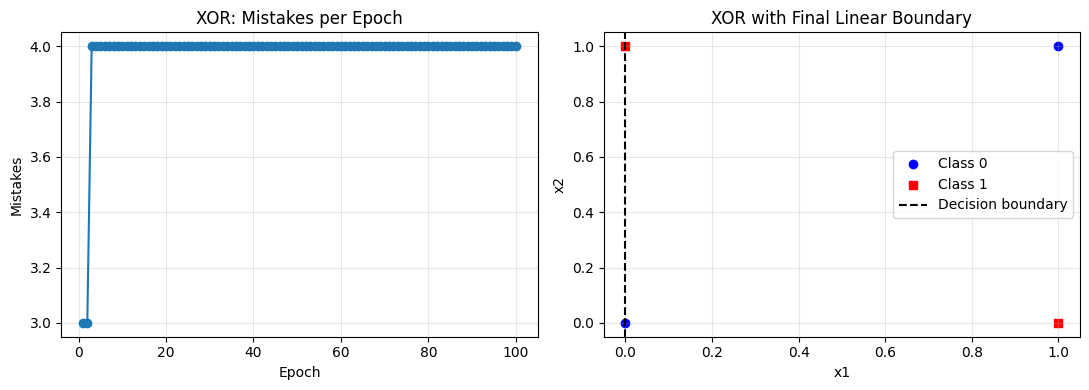

In [9]:
# Task 4.1 — Watch the perceptron fail on XOR

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

w_xor, b_xor, xor_mistakes = train_perceptron(
    X_xor, y_xor, eta=0.1, max_epochs=100
)

print("Final mistakes in last epoch:", xor_mistakes[-1])
print("Final weights:", w_xor)
print("Final bias:", b_xor)
print("Did it reach zero mistakes?", xor_mistakes[-1] == 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(xor_mistakes) + 1), xor_mistakes, marker='o')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mistakes')
axes[0].set_title('XOR: Mistakes per Epoch')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1],
                color='blue', marker='o', label='Class 0')
axes[1].scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1],
                color='red', marker='s', label='Class 1')
plot_boundary(axes[1], w_xor, b_xor)
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')
axes[1].set_title('XOR with Final Linear Boundary')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** The perceptron does not reach zero mistakes on XOR, even after 100 epochs. XOR places the positive examples on opposite corners and the negative examples on the other two corners, so one straight line cannot separate the classes.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [10]:
# Task 4.2 — Random search for an XOR solution

def check_xor(w, b):
    return (
        np.dot(w, [0, 0]) + b < 0 and
        np.dot(w, [0, 1]) + b >= 0 and
        np.dot(w, [1, 0]) + b >= 0 and
        np.dot(w, [1, 1]) + b < 0
    )

random_weights = np.random.uniform(-5, 5, (10000, 2))
random_biases = np.random.uniform(-5, 5, 10000)

passing = []
for candidate_w, candidate_b in zip(random_weights, random_biases):
    if check_xor(candidate_w, candidate_b):
        passing.append((candidate_w, candidate_b))
        break

print("Number of passing triples found:", len(passing))
if len(passing) == 0:
    print("No solution found")
else:
    print("First passing triple:", passing[0])

Number of passing triples found: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [11]:
# Task 5.1 — Train and evaluate a scikit-learn perceptron on Iris

X_iris = iris.data[:, (2, 3)]  # Petal length and petal width
y_iris = (iris.target == 0).astype(int)  # Setosa = 1, all other flowers = 0

X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=42, stratify=y_iris
)

iris_perceptron = Perceptron(random_state=42)
iris_perceptron.fit(X_train, y_train)
y_pred = iris_perceptron.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=['Rest', 'Setosa']))
print("coef_:", iris_perceptron.coef_)
print("intercept_:", iris_perceptron.intercept_)

Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** `coef_` contains the learned weights (w), while `intercept_` contains the learned bias (b). The confusion matrix and classification report show how well the model separates Setosa from the other two Iris classes.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

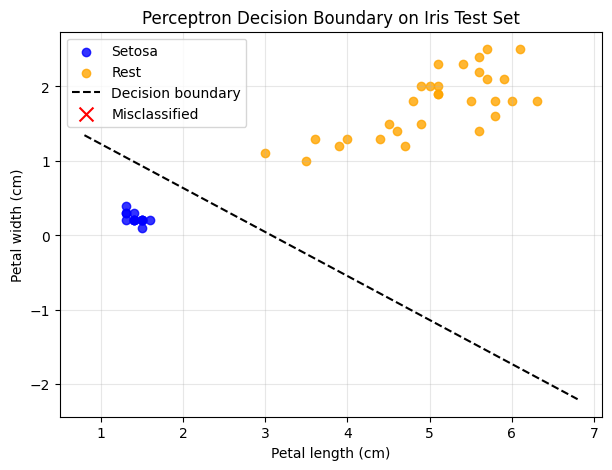

Misclassified test points: 0 out of 45


In [12]:
# Task 5.2 — Visualise the learned decision boundary

fig, ax = plt.subplots(figsize=(7, 5))
for class_value, color, label in [(1, 'blue', 'Setosa'), (0, 'orange', 'Rest')]:
    mask = y_test == class_value
    ax.scatter(X_test[mask, 0], X_test[mask, 1],
               color=color, label=label, alpha=0.8)

plot_boundary(ax, iris_perceptron.coef_[0], iris_perceptron.intercept_[0],
              x_min=X_test[:, 0].min() - 0.5,
              x_max=X_test[:, 0].max() + 0.5)

misclassified = y_pred != y_test
ax.scatter(X_test[misclassified, 0], X_test[misclassified, 1],
           color='red', marker='x', s=100, label='Misclassified')
ax.set_xlabel('Petal length (cm)')
ax.set_ylabel('Petal width (cm)')
ax.set_title('Perceptron Decision Boundary on Iris Test Set')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

print("Misclassified test points:", int(misclassified.sum()), "out of", len(y_test))

**Interpretation:** The model misclassified **0 of 45** test flowers. The boundary is a straight line because the perceptron calculates a linear weighted sum before applying its step function.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [13]:
# Task 5.3 — Effect of learning rate

learning_rate_results = []
learning_rate_predictions = {}

for eta_value in [0.001, 0.1, 10.0]:
    model = Perceptron(eta0=eta_value, random_state=42)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    learning_rate_predictions[eta_value] = predictions
    learning_rate_results.append({
        'eta0': eta_value,
        'accuracy': accuracy_score(y_test, predictions),
        'n_iter_': model.n_iter_,
        'coef_': model.coef_[0].copy()
    })

learning_rate_table = pd.DataFrame(learning_rate_results)
display(learning_rate_table)
print("Predictions identical (0.001 vs 0.1):",
      np.array_equal(learning_rate_predictions[0.001], learning_rate_predictions[0.1]))
print("Predictions identical (0.1 vs 10.0):",
      np.array_equal(learning_rate_predictions[0.1], learning_rate_predictions[10.0]))

,eta0,accuracy,n_iter_,coef_
0,0.001,1.0,6,"[-0.0012999999999999993, -0.0022]"
1,0.100,1.0,7,"[-0.12999999999999995, -0.21999999999999997]"
2,10.000,1.0,7,"[-13.0, -22.0]"


Predictions identical (0.001 vs 0.1): True
Predictions identical (0.1 vs 10.0): True


**Interpretation:** All three learning rates achieved **100% accuracy**, and their test predictions were identical. The learned weight magnitudes changed with `eta0` (`[-0.0013, -0.0022]`, `[-0.13, -0.22]`, and `[-13, -22]`), showing that η changes the size of updates even when the final class predictions stay the same.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [14]:
# Task 6.1 — Perceptron on all three Iris classes

X_all = iris.data
y_all = iris.target

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

multi_perceptron = Perceptron(random_state=42, max_iter=1000)
multi_perceptron.fit(X_train_all, y_train_all)
multi_pred = multi_perceptron.predict(X_test_all)

print("Classification report:\n",
      classification_report(y_test_all, multi_pred, target_names=iris.target_names))
print("Confusion matrix:\n", confusion_matrix(y_test_all, multi_pred))
print("coef_.shape:", multi_perceptron.coef_.shape)

Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Interpretation:** `coef_.shape` is **(3, 4)**, meaning there are three class-specific weight rows and four feature weights in each row. **Versicolor** was hardest to classify: the confusion matrix shows 0 of its 15 test examples were correctly predicted; 14 were predicted as Setosa and 1 as Virginica.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [15]:
# Task 6.2 — Compare Perceptron with Logistic Regression

logistic_model = LogisticRegression(random_state=42, max_iter=200)
logistic_model.fit(X_train_all, y_train_all)
logistic_pred = logistic_model.predict(X_test_all)

comparison = pd.DataFrame([
    {
        'Model': 'Perceptron',
        'Accuracy': accuracy_score(y_test_all, multi_pred),
        'Macro-F1': f1_score(y_test_all, multi_pred, average='macro')
    },
    {
        'Model': 'Logistic Regression',
        'Accuracy': accuracy_score(y_test_all, logistic_pred),
        'Macro-F1': f1_score(y_test_all, logistic_pred, average='macro')
    }
])
display(comparison)

,Model,Accuracy,Macro-F1
0,Perceptron,0.666667,0.549853
1,Logistic Regression,0.933333,0.933259


**Interpretation:** Logistic Regression performed better on this split: accuracy was **0.933** and macro-F1 was **0.933**, compared with the Perceptron's **0.667** accuracy and **0.550** macro-F1. Logistic Regression uses a smooth sigmoid / probability-based learning objective, while the perceptron uses a step function and updates based on right-or-wrong errors.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Answer:**

1. Weighted sum: `z = (0.5 × 1) + (-0.3 × 2) + 0.2 = 0.1`.
2. Since `z >= 0`, the prediction is `ŷ = 1`.
3. Error: `e = y - ŷ = 0 - 1 = -1`.
4. Update: `w₁ = 0.5 + 0.1(-1)(1) = 0.4`; `w₂ = -0.3 + 0.1(-1)(2) = -0.5`.
5. Bias: `b = 0.2 + 0.1(-1) = 0.1`.

**Updated values:** `w = [0.4, -0.5]`, `b = 0.1`.

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Answer:**

The decision boundary is `0.3x₁ + 0.2x₂ - 0.4 = 0`.

Solving for `x₂`: `x₂ = 2 - 1.5x₁`.

For point `(1, 1)`, `z = 0.3(1) + 0.2(1) - 0.4 = 0.1`. Since `z >= 0`, the point is on the class 1 side and its prediction is `ŷ = 1`.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**Answer:**

(a) The four conditions require `b < 0`, `w₂ + b >= 0`, `w₁ + b >= 0`, and `w₁ + w₂ + b < 0`. The middle two give `w₁ + w₂ >= -2b`. But the last condition gives `w₁ + w₂ < -b`. Since `b < 0`, we have `-2b > -b`, so these conditions contradict each other. Therefore, no single linear perceptron can satisfy all four XOR conditions.

(b) XOR points are `(0,0)` and `(1,1)` in class 0, and `(0,1)` and `(1,0)` in class 1. The classes occupy opposite corners, so one straight line cannot separate them.

(c) Add a hidden layer with nonlinear activation functions. A multilayer perceptron can learn XOR.

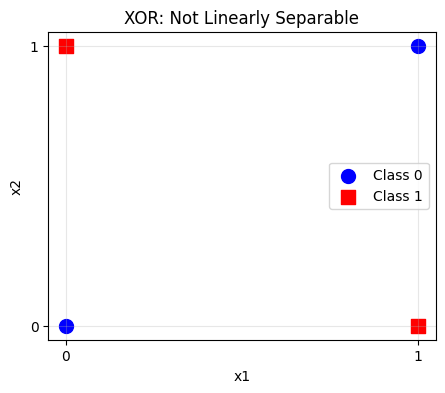

In [16]:
# XOR sketch: opposite corners belong to the same class

plt.figure(figsize=(5, 4))
plt.scatter([0, 1], [0, 1], color='blue', marker='o', s=100, label='Class 0')
plt.scatter([0, 1], [1, 0], color='red', marker='s', s=100, label='Class 1')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('XOR: Not Linearly Separable')
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [17]:
# Q4 — Add sepal length (feature 0) to the Part 5 features

X_iris_extended = iris.data[:, (0, 2, 3)]
X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_iris_extended, y_iris, test_size=0.30, random_state=42, stratify=y_iris
)

extended_model = Perceptron(random_state=42)
extended_model.fit(X_train_ext, y_train_ext)
extended_pred = extended_model.predict(X_test_ext)

base_accuracy = accuracy_score(y_test, y_pred)
base_macro_f1 = f1_score(y_test, y_pred, average='macro')
extended_accuracy = accuracy_score(y_test_ext, extended_pred)
extended_macro_f1 = f1_score(y_test_ext, extended_pred, average='macro')

print("Original features (2, 3) — accuracy:", base_accuracy,
      "| macro-F1:", base_macro_f1)
print("Extended features (0, 2, 3) — accuracy:", extended_accuracy,
      "| macro-F1:", extended_macro_f1)

Original features (2, 3) — accuracy: 1.0 | macro-F1: 1.0
Extended features (0, 2, 3) — accuracy: 1.0 | macro-F1: 1.0


**Analysis:** Both models scored **1.00 accuracy** and **1.00 macro-F1** on this test split. Adding sepal length did **not** improve the measured performance because the original two-feature model was already perfect on these 45 test examples.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Hand-built perceptron accuracy: 0.8166666666666667
Hand-built epochs: 100
Hand-built final weights: [0.25367668 0.03676208]
Hand-built final bias: 0.10000000000000003

Scikit-learn accuracy: 0.7666666666666667
Scikit-learn n_iter_: 14
Scikit-learn weights: [ 1.16050566 -0.19903701]
Scikit-learn bias: 1.0


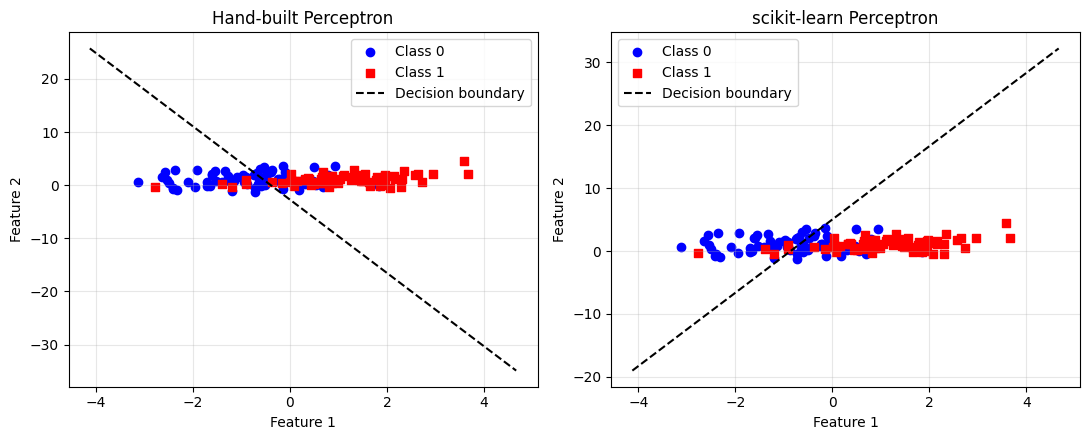

In [18]:
# Q5 — Synthetic binary classification data

from sklearn.metrics import accuracy_score

X_synthetic, y_synthetic = make_classification(
    n_samples=200, n_features=2, n_redundant=0,
    n_clusters_per_class=1, random_state=42
)

X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(
    X_synthetic, y_synthetic, test_size=0.30,
    random_state=42, stratify=y_synthetic
)

# Our own implementation
w_syn, b_syn, syn_mistakes = train_perceptron(
    X_syn_train, y_syn_train, eta=0.1, max_epochs=100
)
syn_hand_pred = np.array([
    predict(w_syn, row, b_syn) for row in X_syn_test
])

# scikit-learn implementation
syn_sklearn = Perceptron(random_state=42, max_iter=1000)
syn_sklearn.fit(X_syn_train, y_syn_train)
syn_sklearn_pred = syn_sklearn.predict(X_syn_test)

print("Hand-built perceptron accuracy:", accuracy_score(y_syn_test, syn_hand_pred))
print("Hand-built epochs:", len(syn_mistakes))
print("Hand-built final weights:", w_syn)
print("Hand-built final bias:", b_syn)
print("\nScikit-learn accuracy:", accuracy_score(y_syn_test, syn_sklearn_pred))
print("Scikit-learn n_iter_:", syn_sklearn.n_iter_)
print("Scikit-learn weights:", syn_sklearn.coef_[0])
print("Scikit-learn bias:", syn_sklearn.intercept_[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, weights, bias, title in [
    (axes[0], w_syn, b_syn, 'Hand-built Perceptron'),
    (axes[1], syn_sklearn.coef_[0], syn_sklearn.intercept_[0], 'scikit-learn Perceptron')
]:
    ax.scatter(X_syn_train[y_syn_train == 0, 0], X_syn_train[y_syn_train == 0, 1],
               color='blue', marker='o', label='Class 0')
    ax.scatter(X_syn_train[y_syn_train == 1, 0], X_syn_train[y_syn_train == 1, 1],
               color='red', marker='s', label='Class 1')
    plot_boundary(ax, weights, bias,
                  x_min=X_synthetic[:, 0].min() - 1,
                  x_max=X_synthetic[:, 0].max() + 1)
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:** The hand-built perceptron reached **0.817 test accuracy** after 100 epochs; it did not stop early because it did not reach a zero-mistake epoch. Scikit-learn reached **0.767 test accuracy** in 14 epochs. Their weights and biases differ because the implementations have different training / stopping details; the two plotted boundaries show the resulting linear separators.